In [4]:
import pandas as pd

vacancies = pd.read_csv("data/vacancies_rows.csv")
skills = pd.read_csv("data/skills_rows.csv")
vacancy_skills = pd.read_csv("data/vacancy_skills_rows.csv")

print("Vacancies:", vacancies.shape)
print("Skills:", skills.shape)
print("Vacancy-Skills:", vacancy_skills.shape)

Vacancies: (2154, 10)
Skills: (2033, 3)
Vacancy-Skills: (13032, 2)


In [5]:
vacancies.head()

,id,created_at,title,company,source_url,description_raw,experience_years,published_at,location,experience_level
0,1,2026-03-19 00:00:00+00,Data Analyst,CRG,https://www.linkedin.com/jobs/view/data-analys...,Data Analyst\n\n\n\n\nDuration: 6-month contra...,3.0,NaN,NaN,NaN
1,2,2026-03-19 00:00:00+00,Data Analyst,Go Offer,https://www.linkedin.com/jobs/view/data-analys...,Join Go Offer as a Data Analyst with Russian l...,2.0,NaN,NaN,NaN
2,3,2026-03-19 00:00:00+00,Data Analyst (f/m/d),ITRex Group,https://pl.linkedin.com/jobs/view/data-analyst...,About ITRex\n\nTHE PLACE\n\nITRex - AI pioneer...,4.0,NaN,NaN,NaN
3,4,2026-03-19 00:00:00+00,Data Analyst - Fully Remote,Haystack,https://uk.linkedin.com/jobs/view/data-analyst...,Data Analyst\n\nWe're working with a leading g...,0.0,NaN,NaN,NaN
4,5,2026-03-19 00:00:00+00,Data Analyst | Remote,Crossing Hurdles,https://uk.linkedin.com/jobs/view/data-analyst...,Position: Join Expert Network: Business Intell...,0.0,NaN,NaN,NaN


In [6]:
vacancies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2154 entries, 0 to 2153
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                2154 non-null   int64  
 1   created_at        2154 non-null   object 
 2   title             2154 non-null   object 
 3   company           2154 non-null   object 
 4   source_url        2154 non-null   object 
 5   description_raw   1946 non-null   object 
 6   experience_years  1833 non-null   float64
 7   published_at      2138 non-null   object 
 8   location          2129 non-null   object 
 9   experience_level  2138 non-null   object 
dtypes: float64(1), int64(1), object(8)
memory usage: 168.4+ KB


In [7]:
vacancies.isnull().sum()


id                    0
created_at            0
title                 0
company               0
source_url            0
description_raw     208
experience_years    321
published_at         16
location             25
experience_level     16
dtype: int64

In [8]:
skills.head(10)


,id,created_at,name
0,1,2026-03-19 11:24:51.895497+00,SQL
1,2,2026-03-19 11:24:51.909554+00,Agile
2,3,2026-03-19 11:24:51.948616+00,ERP Systems
3,4,2026-03-19 11:24:51.987942+00,Issue Tracking
4,5,2026-03-19 11:24:52.016191+00,Snowflake
5,6,2026-03-19 11:24:52.050583+00,Analytical Skills
6,7,2026-03-19 11:24:52.107682+00,Data Reporting
7,8,2026-03-19 11:24:53.276868+00,Tableau
8,10,2026-03-19 11:24:53.320247+00,Python
9,11,2026-03-19 11:24:53.324561+00,Marketing Attribution


In [9]:
vacancy_skills.head(10)

,vacancy_id,skill_id
0,1,1
1,1,2
2,1,3
3,1,4
4,1,5
5,1,6
6,1,7
7,2,1
8,2,8
9,2,10


In [10]:
job_skills = vacancy_skills.merge(
    skills,
    left_on="skill_id",
    right_on="id",
    how="left"
)

job_skills = job_skills.merge(
    vacancies,
    left_on="vacancy_id",
    right_on="id",
    how="left"
)

job_skills.head()

,vacancy_id,skill_id,id_x,created_at_x,name,id_y,created_at_y,title,company,source_url,description_raw,experience_years,published_at,location,experience_level
0,1,1,1,2026-03-19 11:24:51.895497+00,SQL,1,2026-03-19 00:00:00+00,Data Analyst,CRG,https://www.linkedin.com/jobs/view/data-analys...,Data Analyst\n\n\n\n\nDuration: 6-month contra...,3.0,NaN,NaN,NaN
1,1,2,2,2026-03-19 11:24:51.909554+00,Agile,1,2026-03-19 00:00:00+00,Data Analyst,CRG,https://www.linkedin.com/jobs/view/data-analys...,Data Analyst\n\n\n\n\nDuration: 6-month contra...,3.0,NaN,NaN,NaN
2,1,3,3,2026-03-19 11:24:51.948616+00,ERP Systems,1,2026-03-19 00:00:00+00,Data Analyst,CRG,https://www.linkedin.com/jobs/view/data-analys...,Data Analyst\n\n\n\n\nDuration: 6-month contra...,3.0,NaN,NaN,NaN
3,1,4,4,2026-03-19 11:24:51.987942+00,Issue Tracking,1,2026-03-19 00:00:00+00,Data Analyst,CRG,https://www.linkedin.com/jobs/view/data-analys...,Data Analyst\n\n\n\n\nDuration: 6-month contra...,3.0,NaN,NaN,NaN
4,1,5,5,2026-03-19 11:24:52.016191+00,Snowflake,1,2026-03-19 00:00:00+00,Data Analyst,CRG,https://www.linkedin.com/jobs/view/data-analys...,Data Analyst\n\n\n\n\nDuration: 6-month contra...,3.0,NaN,NaN,NaN


In [11]:
job_skills.columns

Index(['vacancy_id', 'skill_id', 'id_x', 'created_at_x', 'name', 'id_y',
       'created_at_y', 'title', 'company', 'source_url', 'description_raw',
       'experience_years', 'published_at', 'location', 'experience_level'],
      dtype='object')

In [12]:
job_skills.duplicated().sum()

np.int64(0)

In [13]:
job_skills.columns = job_skills.columns.str.lower().str.strip()

job_skills.columns

Index(['vacancy_id', 'skill_id', 'id_x', 'created_at_x', 'name', 'id_y',
       'created_at_y', 'title', 'company', 'source_url', 'description_raw',
       'experience_years', 'published_at', 'location', 'experience_level'],
      dtype='object')

In [14]:
job_skills = job_skills[
    [
        "vacancy_id",
        "skill_id",
        "name",
        "title",
        "company",
        "experience_years",
        "published_at",
        "location",
        "experience_level"
    ]
]

job_skills.head()

,vacancy_id,skill_id,name,title,company,experience_years,published_at,location,experience_level
0,1,1,SQL,Data Analyst,CRG,3.0,NaN,NaN,NaN
1,1,2,Agile,Data Analyst,CRG,3.0,NaN,NaN,NaN
2,1,3,ERP Systems,Data Analyst,CRG,3.0,NaN,NaN,NaN
3,1,4,Issue Tracking,Data Analyst,CRG,3.0,NaN,NaN,NaN
4,1,5,Snowflake,Data Analyst,CRG,3.0,NaN,NaN,NaN


In [15]:
vacancies[[
    "id",
    "title",
    "company",
    "experience_years",
    "published_at",
    "location",
    "experience_level"
]].head(10)

,id,title,company,experience_years,published_at,location,experience_level
0,1,Data Analyst,CRG,3.0,NaN,NaN,NaN
1,2,Data Analyst,Go Offer,2.0,NaN,NaN,NaN
2,3,Data Analyst (f/m/d),ITRex Group,4.0,NaN,NaN,NaN
3,4,Data Analyst - Fully Remote,Haystack,0.0,NaN,NaN,NaN
4,5,Data Analyst | Remote,Crossing Hurdles,0.0,NaN,NaN,NaN
5,6,Data Analyst | Remote,Crossing Hurdles,0.0,NaN,NaN,NaN
6,7,Data Analyst (Product),Revolut,5.0,NaN,NaN,NaN
7,8,Data Analyst,Go Offer,NaN,NaN,NaN,NaN
8,9,Reporting Analyst | Remote,Crossing Hurdles,NaN,NaN,NaN,NaN
9,10,Data Analyst,StatusNeo,1.0,NaN,NaN,NaN


In [16]:
vacancies["description_raw"].isnull().sum()

np.int64(208)

In [17]:
vacancies.shape

(2154, 10)

In [18]:
skills.shape

(2033, 3)

In [19]:
vacancy_skills.shape

(13032, 2)

In [20]:
top_skills = (
    job_skills["name"]
    .value_counts()
    .head(10)
)

top_skills

name
SQL                   1298
Python                 760
Excel                  692
Tableau                685
Power BI               568
R                      395
Data Visualization     248
Data Analysis          207
SAS                    169
Data Modeling          166
Name: count, dtype: int64

In [21]:
top_roles = vacancies["title"].value_counts().head(15)

top_roles

title
Data Analyst                648
Senior Data Analyst          91
Business Data Analyst        42
Junior Data Analyst          35
Data analyst                 21
Data Analyst II              20
Data Analyst Intern          17
Marketing Data Analyst       14
DATA ANALYST                 10
Data Analyst I               10
Healthcare Data Analyst      10
Data Analyst (m/w/d)          9
Lead Data Analyst             8
Sr. Data Analyst              8
Remote Data Analyst Jobs      8
Name: count, dtype: int64

In [22]:
vacancies["title_clean"] = (
    vacancies["title"]
    .str.strip()
    .str.lower()
)

vacancies["title_clean"].value_counts().head(15)

title_clean
data analyst                680
senior data analyst          94
business data analyst        43
junior data analyst          35
data analyst ii              23
data analyst intern          18
marketing data analyst       14
data analyst i               11
healthcare data analyst      10
data analyst (m/w/d)          9
lead data analyst             9
remote data analyst jobs      8
sr. data analyst              8
financial data analyst        7
sr data analyst               7
Name: count, dtype: int64

In [23]:
vacancies["title_clean"] = (
    vacancies["title"]
    .str.strip()
    .str.lower()
)

In [24]:
job_skills = job_skills.merge(
    vacancies[["id", "title_clean"]],
    left_on="vacancy_id",
    right_on="id",
    how="left"
)

job_skills = job_skills.drop(columns=["id"])

job_skills[["title", "title_clean", "name"]].head(10)

,title,title_clean,name
0,Data Analyst,data analyst,SQL
1,Data Analyst,data analyst,Agile
2,Data Analyst,data analyst,ERP Systems
3,Data Analyst,data analyst,Issue Tracking
4,Data Analyst,data analyst,Snowflake
5,Data Analyst,data analyst,Analytical Skills
6,Data Analyst,data analyst,Data Reporting
7,Data Analyst,data analyst,SQL
8,Data Analyst,data analyst,Tableau
9,Data Analyst,data analyst,Python


In [25]:
data_analyst_skills = (
    job_skills[
        job_skills["title_clean"] == "data analyst"
    ]["name"]
    .value_counts()
    .head(15)
)

data_analyst_skills

name
SQL                   468
Python                258
Tableau               241
Excel                 235
Power BI              221
R                     121
Data Visualization     91
Data Analysis          75
Data Modeling          65
Looker                 51
ETL                    50
AWS                    50
Snowflake              48
Reporting              45
SAS                    42
Name: count, dtype: int64

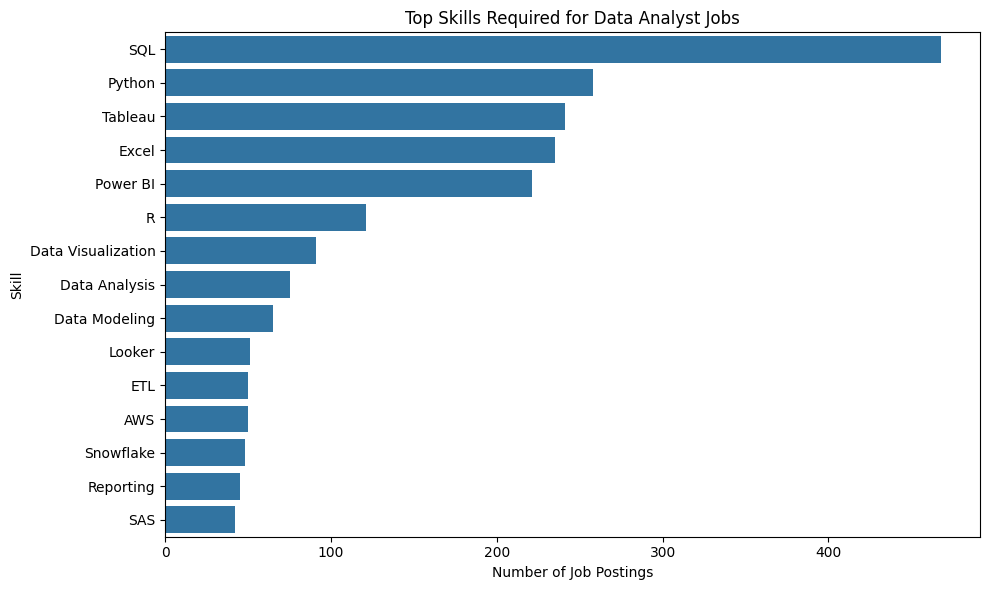

In [26]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    x=data_analyst_skills.values,
    y=data_analyst_skills.index
)

plt.title("Top Skills Required for Data Analyst Jobs")
plt.xlabel("Number of Job Postings")
plt.ylabel("Skill")
plt.tight_layout()

plt.savefig(
    "outputs/top_data_analyst_skills.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()


In [27]:
# Select the most common roles
top_role_names = (
    vacancies["title_clean"]
    .value_counts()
    .head(10)
    .index
)

# Select the top 10 skills
top_skill_names = (
    job_skills["name"]
    .value_counts()
    .head(10)
    .index
)

# Create Role vs Skill matrix
skill_role_matrix = pd.crosstab(
    job_skills["title_clean"],
    job_skills["name"]
)

# Keep only top roles and top skills
skill_role_matrix = skill_role_matrix.loc[
    skill_role_matrix.index.intersection(top_role_names),
    skill_role_matrix.columns.intersection(top_skill_names)
]
plt.savefig("outputs/skill_vs_role_matrix.png", bbox_inches="tight", dpi=300)
skill_role_matrix

name,Data Analysis,Data Modeling,Data Visualization,Excel,Power BI,Python,R,SAS,SQL,Tableau
title_clean,,,,,,,,,,
business data analyst,5,5,4,13,10,14,8,2,26,11
data analyst,75,65,91,235,221,258,121,42,468,241
data analyst (m/w/d),0,0,0,0,3,1,2,1,5,2
data analyst i,2,0,3,4,6,2,0,0,7,4
data analyst ii,4,3,6,5,12,17,10,4,18,13
data analyst intern,3,1,6,8,7,11,5,0,10,7
healthcare data analyst,0,1,0,3,1,0,0,1,9,0
junior data analyst,2,1,1,18,16,16,8,0,20,13
marketing data analyst,0,1,1,3,4,5,3,0,8,5


<Figure size 640x480 with 0 Axes>

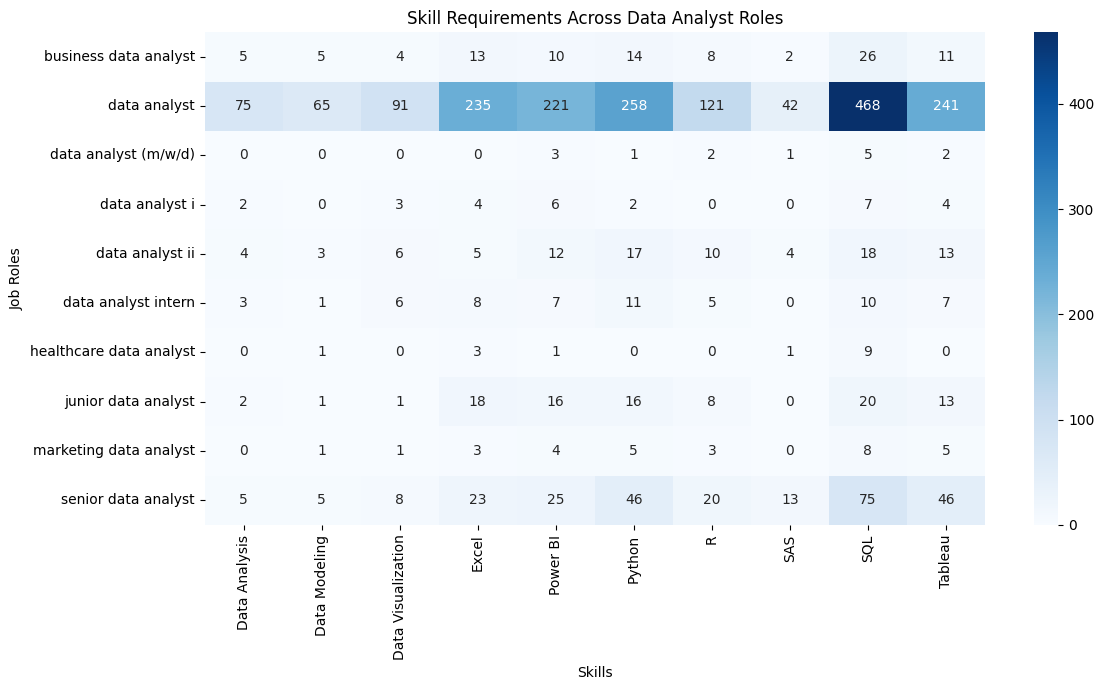

In [28]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    skill_role_matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Skill Requirements Across Data Analyst Roles")
plt.xlabel("Skills")
plt.ylabel("Job Roles")
plt.tight_layout()

plt.show()

In [29]:
experience_summary = vacancies["experience_years"].describe()

experience_summary

count    1833.000000
mean        1.409711
std         2.025938
min         0.000000
25%         0.000000
50%         0.000000
75%         2.000000
max        25.000000
Name: experience_years, dtype: float64

In [ ]:
experience_groups = pd.cut(
    vacancies["experience_years"],
    bins=[-1, 0, 2, 5, 10, float("inf")],
    labels=[
        "0 years",
        "1–2 years",
        "3–5 years",
        "6–10 years",
        "10+ years"
    ]
)

experience_counts = experience_groups.value_counts().sort_index()

experience_counts

experience_years
0 years       1011
1–2 years      390
3–5 years      376
6–10 years      53
10+ years        3
Name: count, dtype: int64

: 

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=experience_counts.index,
    y=experience_counts.values
)

plt.title("Experience Requirements in Data Analyst Job Postings")
plt.xlabel("Required Experience")
plt.ylabel("Number of Job Postings")
plt.tight_layout()

plt.savefig("outputs/experience_requirements.png", bbox_inches="tight", dpi=300)
plt.show()

In [ ]:
import pandas as pd

experience_groups = pd.cut(
    vacancies["experience_years"],
    bins=[-1, 0, 2, 5, 10, float("inf")],
    labels=["0 years", "1–2 years", "3–5 years", "6–10 years", "10+ years"]
)

experience_counts = experience_groups.value_counts().sort_index()

experience_counts

experience_years
0 years       1011
1–2 years      390
3–5 years      376
6–10 years      53
10+ years        3
Name: count, dtype: int64

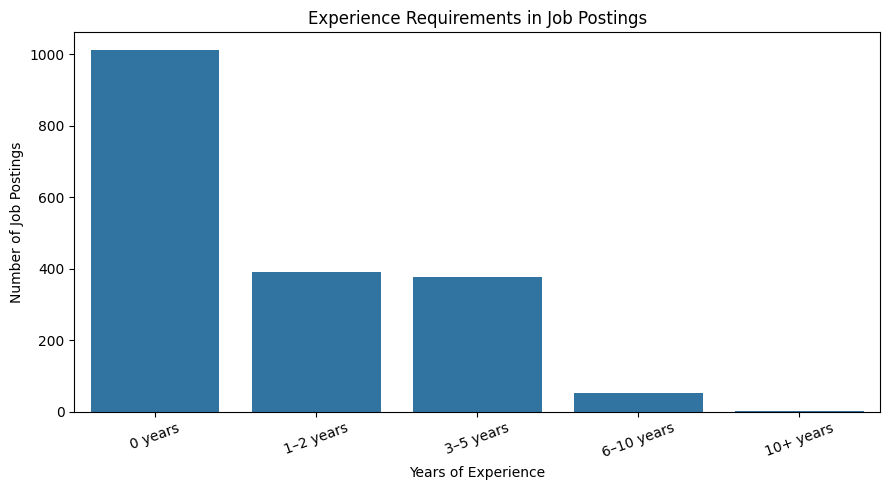

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    x=experience_counts.index,
    y=experience_counts.values
)

plt.title("Experience Requirements in Job Postings")
plt.xlabel("Years of Experience")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    "outputs/experience_requirements.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

In [ ]:
location_summary = vacancies["location"].value_counts(dropna=False).head(15)

location_summary

location
Anywhere              167
United States         133
New York, NY           67
Kuala Lumpur           47
Singapore              32
San Francisco, CA      29
NaN                    25
India                  24
Austin, TX             24
Paris, France          23
Los Angeles, CA        23
Chicago, IL            22
  United States        21
 Anywhere              20
United Kingdom         19
Name: count, dtype: int64

In [ ]:
vacancies["location_clean"] = (
    vacancies["location"]
    .astype("string")
    .str.strip()
)

vacancies["location_clean"].value_counts().head(20)

NameError: name 'vacancies' is not defined

In [ ]:
top_locations = (
    vacancies["location_clean"]
    .dropna()
    .value_counts()
    .head(15)
)

top_locations

NameError: name 'vacancies' is not defined

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("Top Job Locations")
plt.xlabel("Number of Job Postings")
plt.ylabel("Location")
plt.tight_layout()
plt.savefig(
    "outputs/top_job_locations.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

NameError: name 'top_locations' is not defined

<Figure size 1000x600 with 0 Axes>

In [ ]:
vacancies["location_clean"] = (
    vacancies["location"]
    .astype("string")
    .str.strip()
)

top_locations = (
    vacancies["location_clean"]
    .value_counts()
    .head(10)
)

top_locations

location_clean
Anywhere             187
United States        154
New York, NY          67
Kuala Lumpur          47
Singapore             32
San Francisco, CA     29
India                 24
Austin, TX            24
Paris, France         23
Los Angeles, CA       23
Name: count, dtype: Int64

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("Top 10 Job Locations")
plt.xlabel("Number of Job Postings")
plt.ylabel("Location")
plt.tight_layout()

plt.savefig(
    "outputs/top_job_locations.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

NameError: name 'top_locations' is not defined

<Figure size 1000x600 with 0 Axes>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the top 10 job locations
vacancies["location_clean"] = (
    vacancies["location"].astype("string").str.strip()
)

top_locations = (
    vacancies["location_clean"]
    .dropna()
    .value_counts()
    .head(10)
)

# Create and save the chart
plt.figure(figsize=(10, 6))
sns.barplot(x=top_locations.values, y=top_locations.index)

plt.title("Top 10 Job Locations")
plt.xlabel("Number of Job Postings")
plt.ylabel("Location")
plt.tight_layout()

plt.savefig(
    "outputs/top_job_locations.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

NameError: name 'vacancies' is not defined

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets again
vacancies = pd.read_csv("data/vacancies_rows.csv")
skills = pd.read_csv("data/skills_rows.csv")
vacancy_skills = pd.read_csv("data/vacancy_skills_rows.csv")

# Clean job titles
vacancies["title_clean"] = (
    vacancies["title"].str.strip().str.lower()
)

print("Datasets loaded successfully!")
print("Vacancies:", vacancies.shape)

Datasets loaded successfully!
Vacancies: (2154, 11)


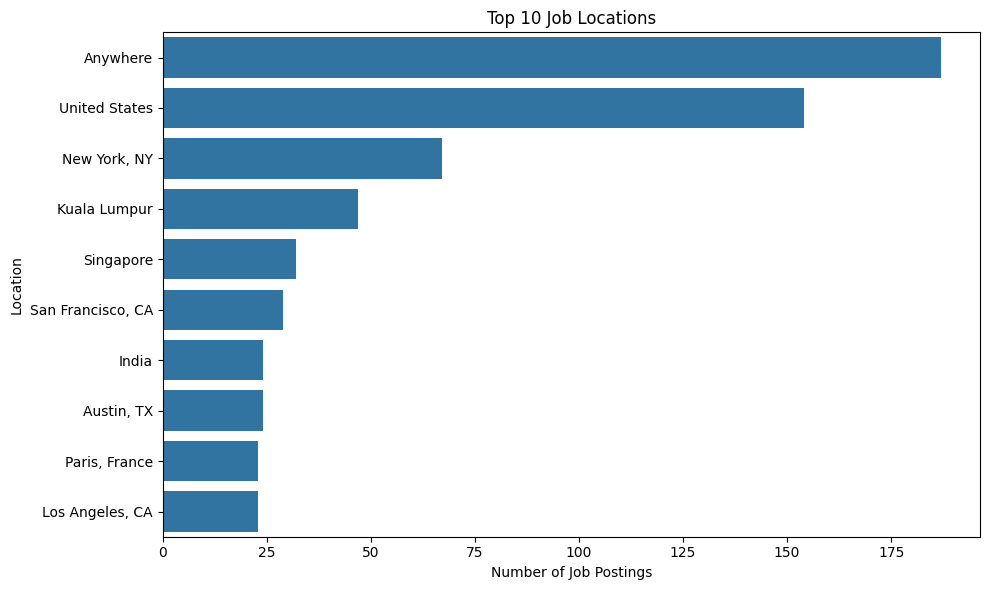

In [3]:
# Calculate the top 10 job locations
vacancies["location_clean"] = (
    vacancies["location"].astype("string").str.strip()
)

top_locations = (
    vacancies["location_clean"]
    .dropna()
    .value_counts()
    .head(10)
)

# Create the chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("Top 10 Job Locations")
plt.xlabel("Number of Job Postings")
plt.ylabel("Location")
plt.tight_layout()

# Save the chart
plt.savefig(
    "outputs/top_job_locations.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

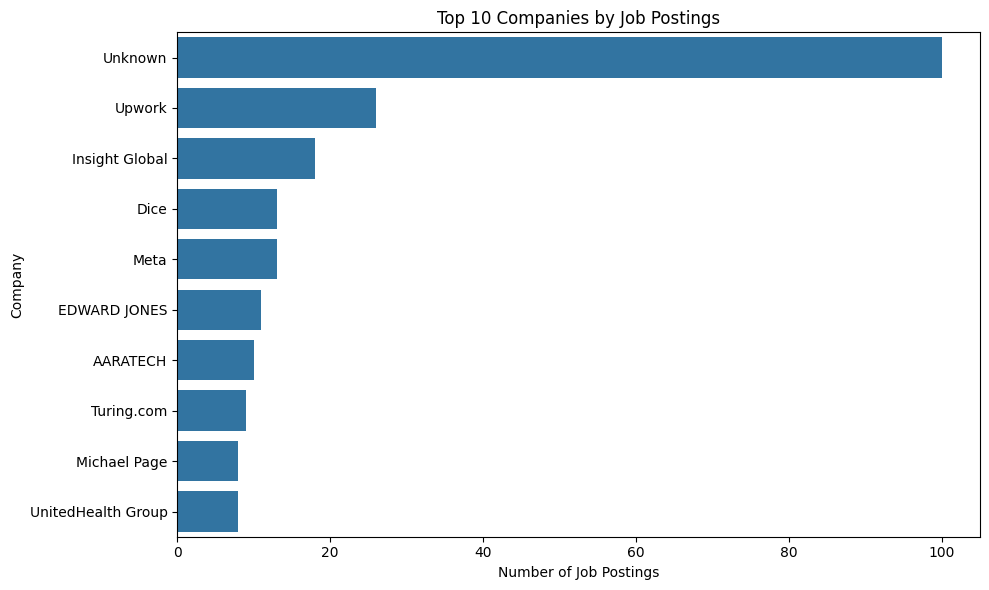

In [4]:
# Calculate top 10 companies
top_companies = (
    vacancies["company"]
    .fillna("Unknown")
    .str.strip()
    .value_counts()
    .head(10)
)

# Create the chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_companies.values,
    y=top_companies.index
)

plt.title("Top 10 Companies by Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Company")
plt.tight_layout()

# Save the chart
plt.savefig(
    "outputs/top_companies.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

In [ ]:
top_companies = (
    vacancies["company"]
    .dropna()
    .str.strip()
    .value_counts()
    .head(15)
)

top_companies

company
Unknown               100
Upwork                 26
Insight Global         18
Dice                   13
Meta                   13
EDWARD JONES           11
AARATECH               10
Turing.com              9
Michael Page            8
UnitedHealth Group      8
Corporate               8
Brooksource             7
Kforce Inc              7
Crossing Hurdles        7
Emprego                 6
Name: count, dtype: int64

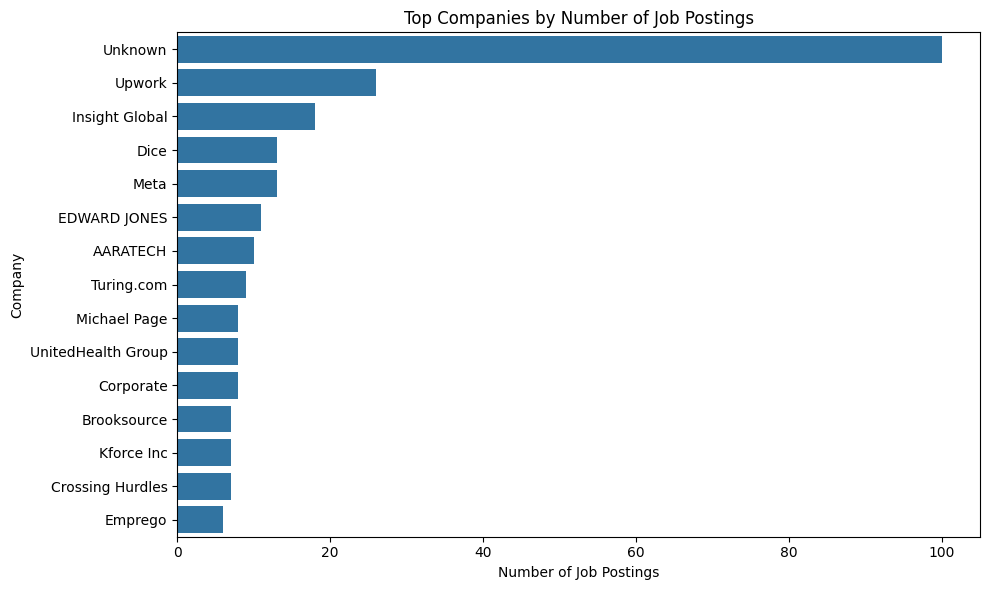

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_companies.values,
    y=top_companies.index
)

plt.title("Top Companies by Number of Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Company")
plt.tight_layout()

plt.show()

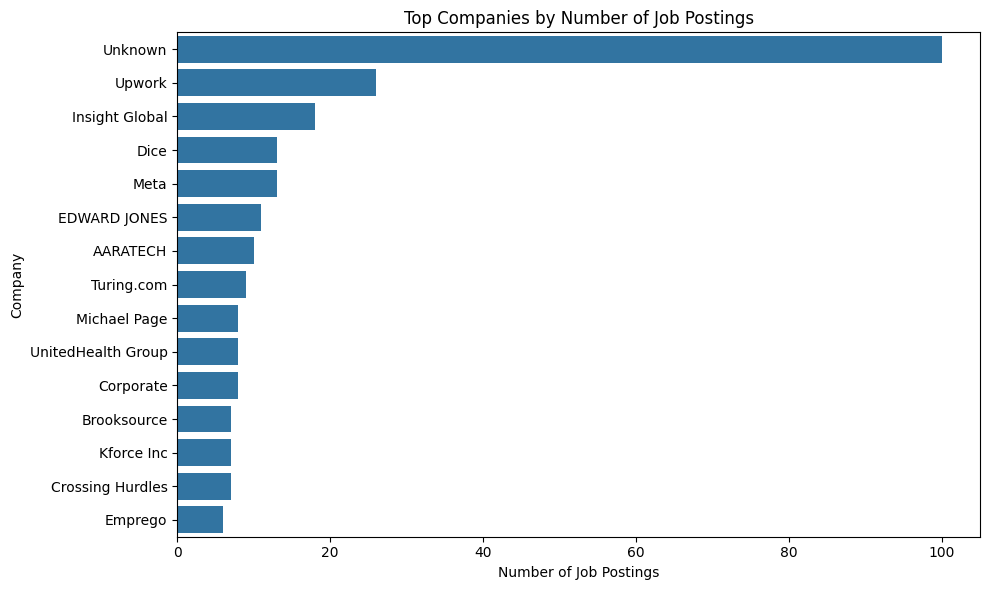

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_companies.values,
    y=top_companies.index
)

plt.title("Top Companies by Number of Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Company")
plt.tight_layout()

plt.show()

In [ ]:
vacancies["created_at"] = pd.to_datetime(
    vacancies["created_at"],
    errors="coerce"
)

vacancies["created_at"].describe()

count                                     34
mean     2026-03-19 19:03:31.764705792+00:00
min                2026-03-18 00:00:00+00:00
25%                2026-03-19 00:00:00+00:00
50%                2026-03-20 00:00:00+00:00
75%                2026-03-21 00:00:00+00:00
max                2026-03-21 00:00:00+00:00
Name: created_at, dtype: object

In [ ]:
key_insights = {
    "Total Job Postings": len(vacancies),
    "Total Skills": len(skills),
    "Data Analyst Jobs": (vacancies["title_clean"] == "data analyst").sum(),
    "Top Skill": data_analyst_skills.index[0],
    "Top Skill Count": data_analyst_skills.iloc[0],
    "Average Experience Required": round(vacancies["experience_years"].mean(), 2),
    "Most Common Experience Group": experience_counts.idxmax(),
    "Top Location": top_locations.index[0],
    "Top Company": top_companies.index[0]
}

key_insights

{'Total Job Postings': 2154,
 'Total Skills': 2033,
 'Data Analyst Jobs': np.int64(680),
 'Top Skill': 'SQL',
 'Top Skill Count': np.int64(468),
 'Average Experience Required': np.float64(1.41),
 'Most Common Experience Group': '0 years',
 'Top Location': 'Anywhere',
 'Top Company': 'Unknown'}

In [ ]:
key_insights_df = pd.DataFrame(
    list(key_insights.items()),
    columns=["Metric", "Value"]
)

key_insights_df

,Metric,Value
0,Total Job Postings,2154
1,Total Skills,2033
2,Data Analyst Jobs,680
3,Top Skill,SQL
4,Top Skill Count,468
5,Average Experience Required,1.41
6,Most Common Experience Group,0 years
7,Top Location,Anywhere
8,Top Company,Unknown


In [ ]:
key_insights_df.to_csv(
    "outputs/linkedin_job_key_insights.csv", index=False)

In [ ]:
skill_role_matrix.to_csv(
    "outputs/skill_vs_role_matrix.csv", index=False)

In [ ]:
experience_df = pd.DataFrame({
    "Experience Group": experience_counts.index,
    "Job Postings": experience_counts.values
})

experience_df.to_csv(
    "outputs/skill_vs_role_matrix.csv", index=False
)

experience_df

,Experience Group,Job Postings
0,0 years,1011
1,1–2 years,390
2,3–5 years,376
3,6–10 years,53
4,10+ years,3


In [ ]:
top_skills_df = pd.DataFrame({
    "Skill": data_analyst_skills.index,
    "Job Postings": data_analyst_skills.values
})

top_skills_df.to_csv(
    "top_data_analyst_skills.csv",
    index=False
)

top_skills_df

,Skill,Job Postings
0,SQL,468
1,Python,258
2,Tableau,241
3,Excel,235
4,Power BI,221
5,R,121
6,Data Visualization,91
7,Data Analysis,75
8,Data Modeling,65
9,Looker,51


In [ ]:
top_locations_df = pd.DataFrame({
    "Location": top_locations.index,
    "Job Postings": top_locations.values
})

top_locations_df.to_csv(
    "top_job_locations.csv",
    index=False
)

top_locations_df

,Location,Job Postings
0,Anywhere,187
1,United States,154
2,"New York, NY",67
3,Kuala Lumpur,47
4,Singapore,32
5,"San Francisco, CA",29
6,India,24
7,"Austin, TX",24
8,"Paris, France",23
9,"Los Angeles, CA",23


In [ ]:
top_companies_df = pd.DataFrame({
    "Company": top_companies.index,
    "Job Postings": top_companies.values
})

top_companies_df.to_csv(
    "top_companies.csv",
    index=False
)

top_companies_df

,Company,Job Postings
0,Unknown,100
1,Upwork,26
2,Insight Global,18
3,Dice,13
4,Meta,13
5,EDWARD JONES,11
6,AARATECH,10
7,Turing.com,9
8,Michael Page,8
9,UnitedHealth Group,8


In [ ]:
import os

output_files = [
    "linkedin_job_key_insights.csv",
    "skill_vs_role_matrix.csv",
    "experience_requirements.csv",
    "top_data_analyst_skills.csv",
    "top_job_locations.csv",
    "top_companies.csv"
]

for file in output_files:
    print(file, "→", "Created" if os.path.exists(file) else "Missing")

linkedin_job_key_insights.csv → Created
skill_vs_role_matrix.csv → Created
experience_requirements.csv → Created
top_data_analyst_skills.csv → Created
top_job_locations.csv → Created
top_companies.csv → Created


In [ ]:
job_skills.to_csv(
    "cleaned_job_skills.csv",
    index=False
)